# Análisis Exploratorio — Producción Agrícola de Chiapas (2003–2023)

Análisis de datos de producción agrícola del SIAP para el estado de Chiapas:
22,098 registros, 124 municipios, 74 cultivos y 21 años de historia.

> Este notebook reemplaza un notebook previo que era una copia del proyecto de
> oncología (METS OPS) y no analizaba agricultura. Ver **GUIA_DE_ESTUDIO.md**.

In [1]:
import sys
sys.path.insert(0, ".")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data, top_crops, summary_table

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)

df = load_data("cierre_agricola_modificado.csv")
df.head()

,Anio,Idestado,Nomestado,Idddr,Nomddr,Idcader,Nomcader,Idmunicipio,Nommunicipio,Idciclo,...,Nomcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion,Clave de municipio,Tasa_siniestralidad
0,2003,7,Chiapas,18,Tuxtla Gutiérrez,1,Tuxtla Gutiérrez,2,Acala,1,...,Maíz grano,286.0,286.0,0.0,715.0,2.50,1450.0,1036750.0,7002.0,0.0
1,2003,7,Chiapas,18,Tuxtla Gutiérrez,1,Tuxtla Gutiérrez,2,Acala,1,...,Sandía,2.0,2.0,0.0,36.0,18.00,2000.0,72000.0,7002.0,0.0
2,2003,7,Chiapas,18,Tuxtla Gutiérrez,1,Tuxtla Gutiérrez,2,Acala,1,...,Sorgo grano,6.0,6.0,0.0,18.0,3.00,1000.0,18000.0,7002.0,0.0
3,2003,7,Chiapas,18,Tuxtla Gutiérrez,1,Tuxtla Gutiérrez,2,Acala,2,...,Cacahuate,83.5,83.5,0.0,131.1,1.57,3000.0,393300.0,7002.0,0.0
4,2003,7,Chiapas,18,Tuxtla Gutiérrez,1,Tuxtla Gutiérrez,2,Acala,2,...,Maíz grano,18499.5,18499.5,0.0,49231.0,2.66,1420.0,69908020.0,7002.0,0.0


## 1. Resumen general del dataset

In [2]:
summary_table(df)

,Indicador,Valor
0,Años,2003–2023
1,Municipios,124
2,Cultivos,74
3,Ciclos,"Otoño-Invierno, Primavera-Verano, Perennes"
4,Modalidades,"Riego, Temporal"
5,Hectáreas sembradas (total),"29,896,640"
6,Hectáreas cosechadas (total),"29,064,016"
7,Producción total (ton),"223,237,596"
8,Valor de producción total (MXN),"$356,491,962,322"


## 2. Cultivos más importantes

Por **valor de producción** (MXN) y por **volumen** (toneladas).

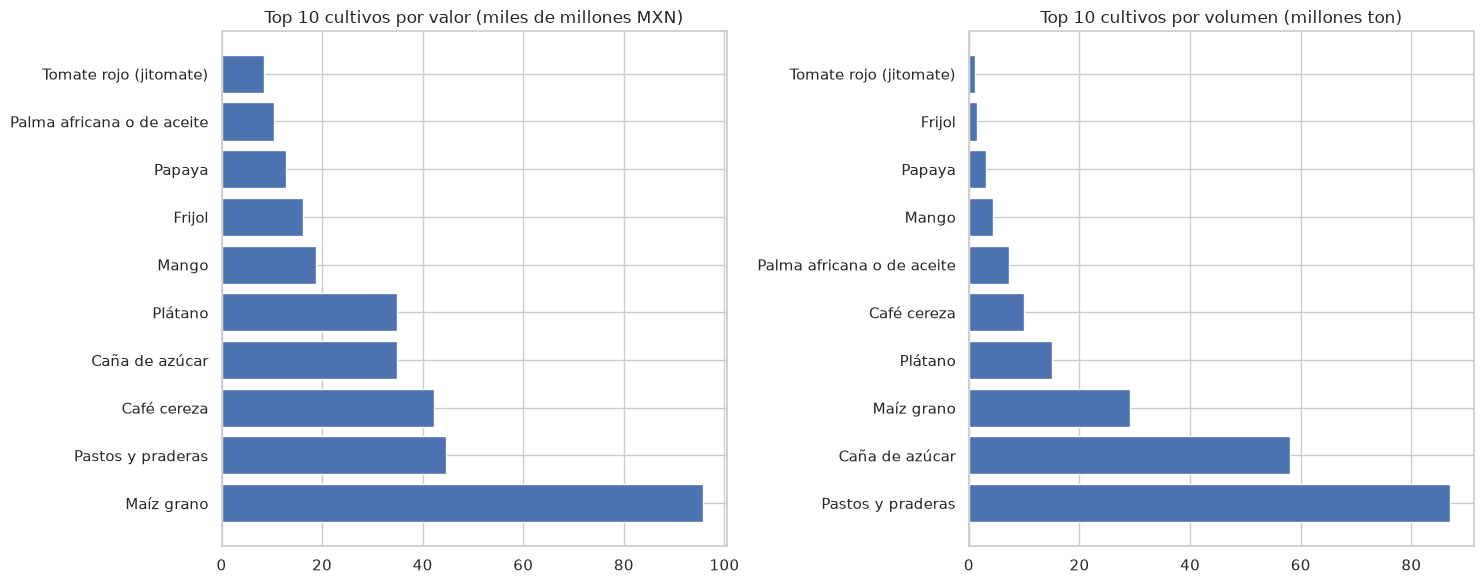

In [3]:
top_valor = top_crops(df, by="Valorproduccion", n=10)
top_volumen = top_crops(df, by="Volumenproduccion", n=10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top_valor["Nomcultivo"], top_valor["Valorproduccion"] / 1e9)
axes[0].set_title("Top 10 cultivos por valor (miles de millones MXN)")
axes[1].barh(top_volumen["Nomcultivo"], top_volumen["Volumenproduccion"] / 1e6)
axes[1].set_title("Top 10 cultivos por volumen (millones ton)")
plt.tight_layout()
plt.show()

## 3. Evolución de la producción (2003–2023)

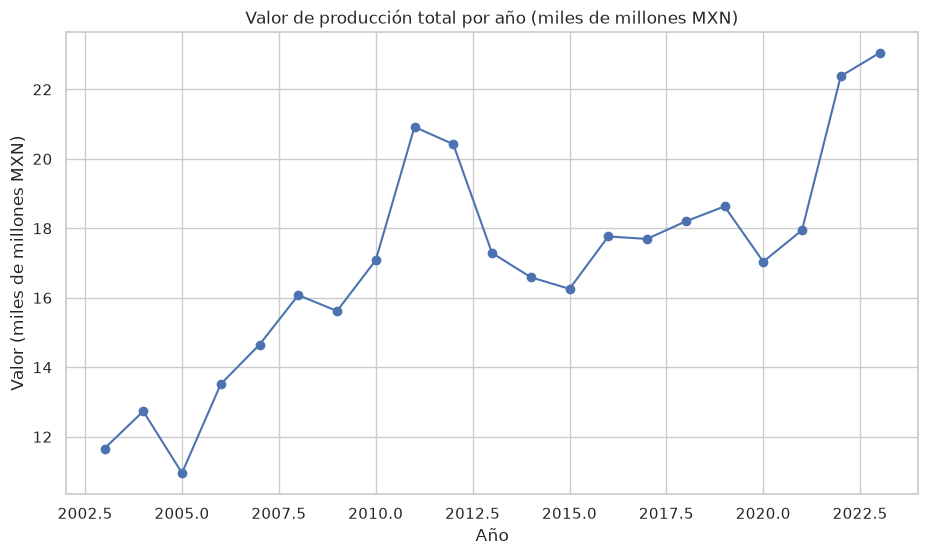

In [4]:
serie = df.groupby("Anio")["Valorproduccion"].sum() / 1e9
plt.plot(serie.index, serie.values, marker="o")
plt.title("Valor de producción total por año (miles de millones MXN)")
plt.xlabel("Año"); plt.ylabel("Valor (miles de millones MXN)")
plt.show()

## 4. Rendimiento por modalidad (riego vs temporal)

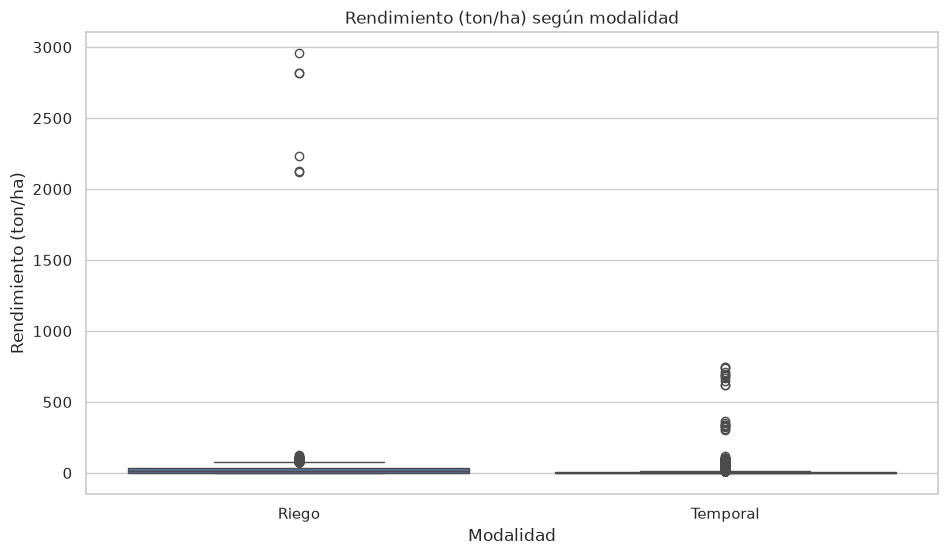

In [5]:
sns.boxplot(data=df, x="Nommodalidad", y="Rendimiento")
plt.title("Rendimiento (ton/ha) según modalidad")
plt.xlabel("Modalidad"); plt.ylabel("Rendimiento (ton/ha)")
plt.show()

## 5. Evolución de precios de los cultivos principales

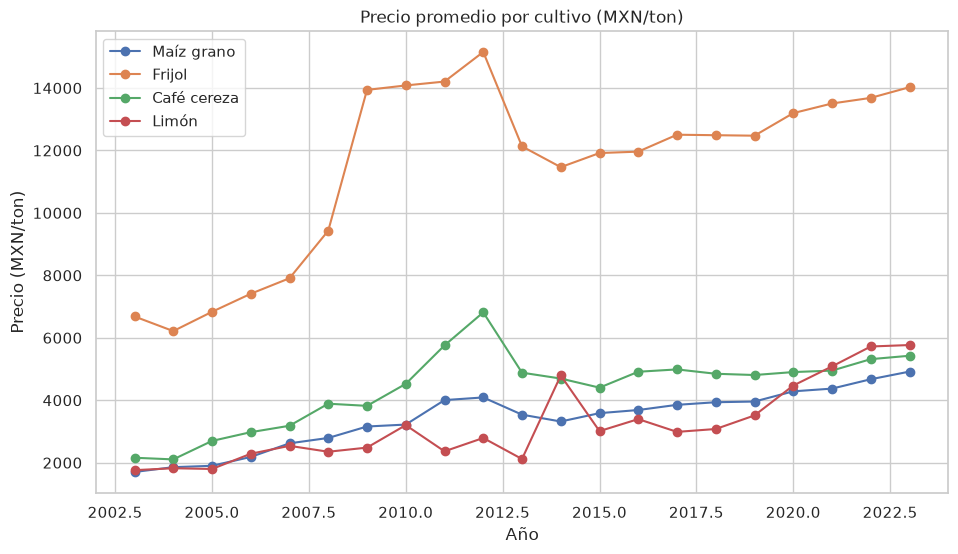

In [6]:
for cultivo in ["Maíz grano", "Frijol", "Café cereza", "Limón"]:
    sub = df[df["Nomcultivo"] == cultivo].groupby("Anio")["Precio"].mean()
    plt.plot(sub.index, sub.values, marker="o", label=cultivo)
plt.title("Precio promedio por cultivo (MXN/ton)")
plt.xlabel("Año"); plt.ylabel("Precio (MXN/ton)")
plt.legend()
plt.show()

## 6. Municipios con mayor valor de producción

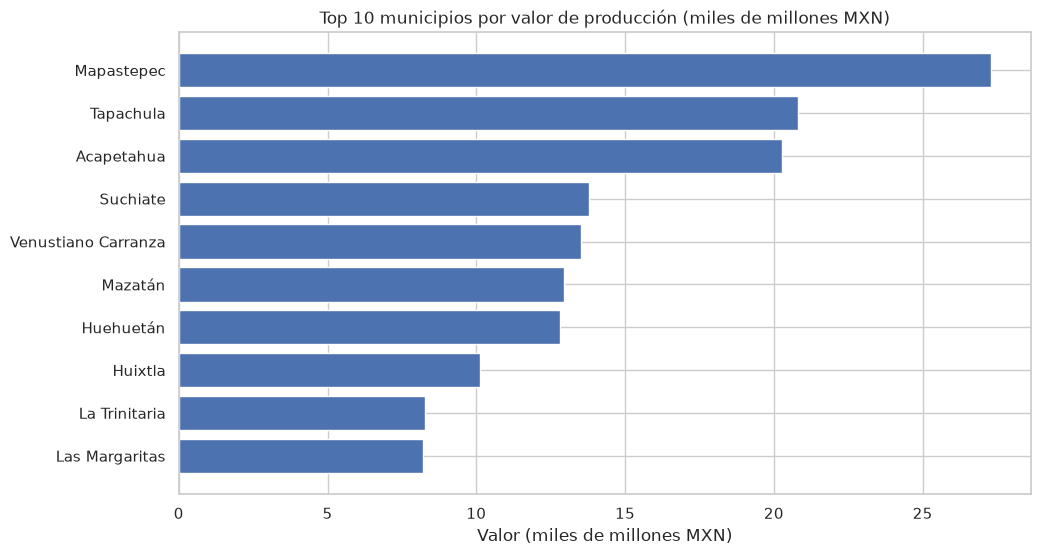

In [7]:
top_mun = (df.groupby("Nommunicipio")["Valorproduccion"].sum()
             .sort_values(ascending=True).tail(10))
plt.barh(top_mun.index, top_mun.values / 1e9)
plt.title("Top 10 municipios por valor de producción (miles de millones MXN)")
plt.xlabel("Valor (miles de millones MXN)")
plt.show()

## 7. Siniestralidad (pérdidas por siniestros)

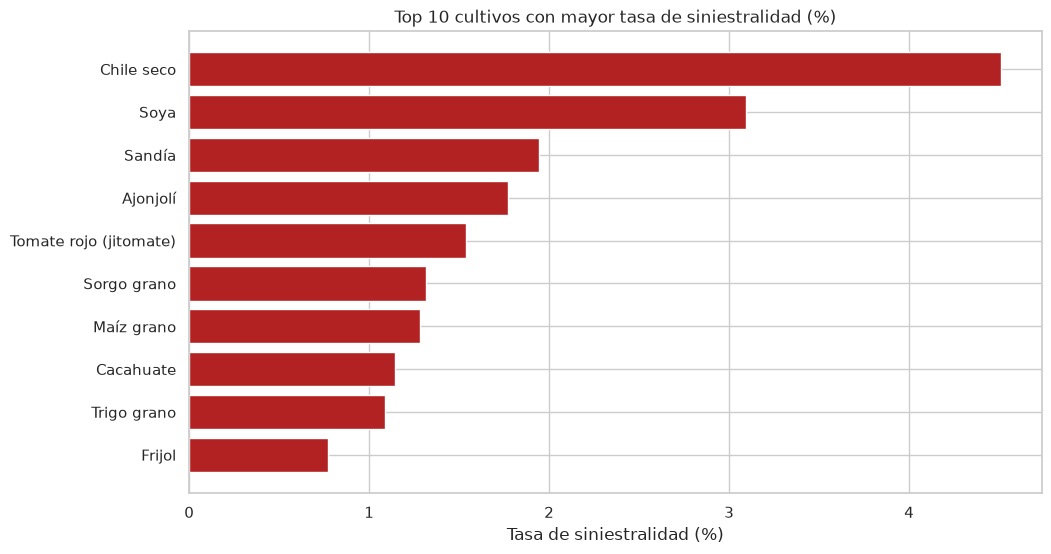

In [8]:
sin = (df.groupby("Nomcultivo")["Tasa_siniestralidad"].mean()
         .sort_values(ascending=True).tail(10))
plt.barh(sin.index, sin.values, color="firebrick")
plt.title("Top 10 cultivos con mayor tasa de siniestralidad (%)")
plt.xlabel("Tasa de siniestralidad (%)")
plt.show()

## 8. Conclusiones

- **Maíz grano** domina por valor ($95.6 mil millones MXN), seguido de **pastos**, **café cereza**, **caña de azúcar** y **plátano**.
- Por **volumen**, los **pastos y praderas** lideran (86.9 M ton), seguidos de caña de azúcar y maíz.
- La **siniestralidad** más alta está en **chile seco** (4.5%) y **soya** (3.1%), cultivos de menor superficie pero más vulnerables.
- Los cultivos de **riego** presentan mayor rendimiento promedio que los de **temporal** (ver boxplot).

*Resultados reproducibles con `python scripts/eda.py` (guarda gráficos en `results/`).*